### Import

In [19]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2
import json
import seaborn as sns

### Latin Hypercube Sampling Function

In [17]:
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # 1. Generate Latin Hypercube Samples
    if seed is not None:
        np.random.seed(seed)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # 2. Transform samples to satisfy sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

### Samplings of 8 samples

In [21]:
seeds = [1,2,3,4,5]
arrays = []
n_samples = 8

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples,
            n_variables=4,
            sum_constraint=270.0,
            seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)

CMYK_values = []

for i, array in enumerate(arrays):
    seed_value = seeds[i]
    
    c_values_str = ", ".join(map(str, array[0]))
    m_values_str = ", ".join(map(str, array[1]))
    y_values_str = ", ".join(map(str, array[2]))
    k_values_str = ", ".join(map(str, array[3]))

    print(f"Results for seed {seed_value}:")
    print("C (blue) values:")
    print(c_values_str)
    print("\nM (red) values:")
    print(m_values_str)
    print("\nY (yellow) values:")
    print(y_values_str)
    print("\nK (black) values:")
    print(k_values_str)
    print("\n" + "-"*50 + "\n")

    CMYK_values.append({
        "Results for seed": seed_value,
        "C (blue) values": c_values_str,
        "M (red) values": m_values_str,
        "Y (yellow) values": y_values_str,
        "K (black) values": k_values_str
    })

with open("CMYK_values.json", "w") as f:
    json.dump(CMYK_values, f, indent=2)

Results for seed 1:
C (blue) values:
32.70559840366913, 97.59323331796845, 68.99239840624564, 7.887770793637806, 59.497681932221674, 172.53467194394005, 28.642748207450367, 85.64920418928037

M (red) values:
107.50286277426395, 81.23789690652443, 17.060869216999055, 13.62459159767195, 128.013489465258, 63.70115225093016, 113.86329554321938, 57.26121332305052

Y (yellow) values:
72.50545544682114, 41.20774501453708, 95.04025946442957, 134.26181881925555, 76.87536151287757, 0.002869765097959732, 60.42469883588295, 17.51537959705464

K (black) values:
57.286083375245774, 49.96112476097003, 88.90647291232578, 114.22581878943474, 5.6134670896427386, 33.76130604003185, 67.06925741344733, 109.57420289061447

--------------------------------------------------

Results for seed 2:
C (blue) values:
117.14957392020146, 58.994578212075844, 74.50254372760647, 44.16310128727662, 12.368343759673595, 83.34445119989928, 56.86819934135977, 64.00253109198023

M (red) values:
107.03228921927882, 89.328823

### Plot

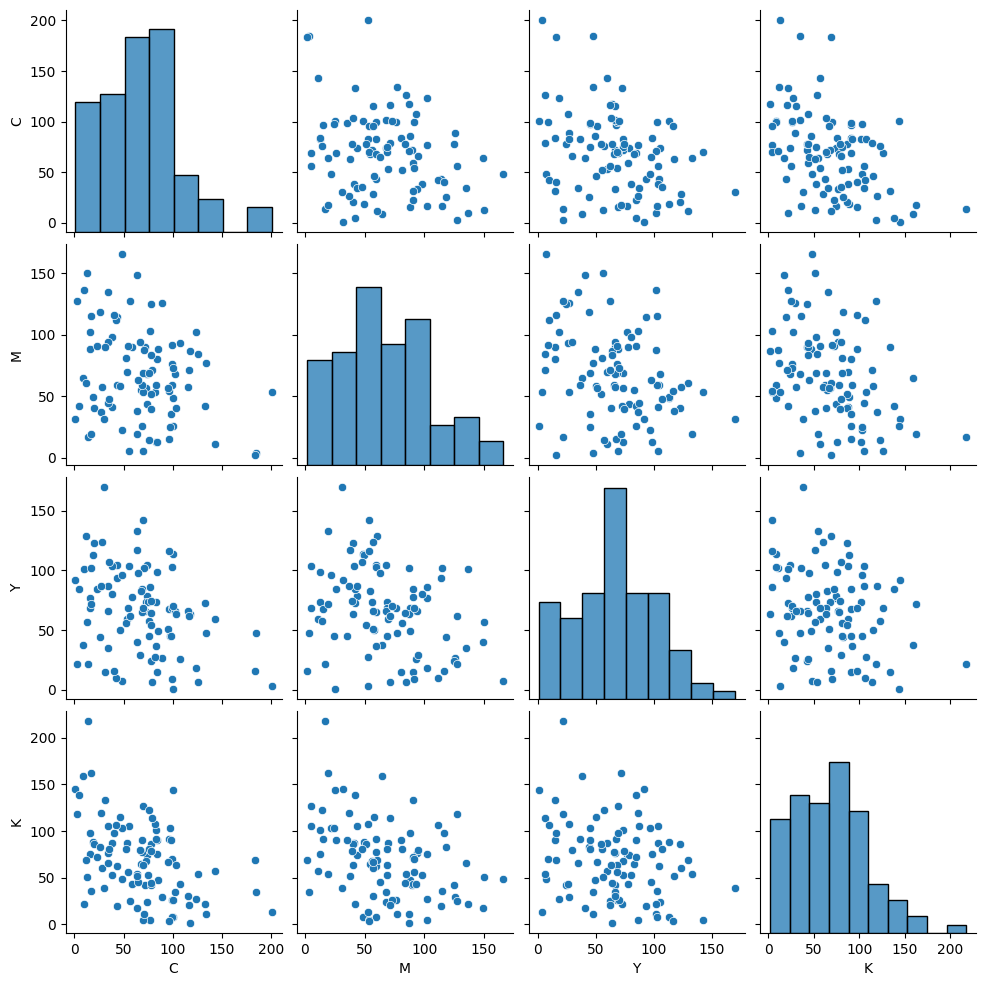

In [20]:
sns.pairplot(df_lhs)
plt.show()

### Testing 4 samples

In [5]:
seeds = [1]
arrays = []
n_samples = 4

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples, n_variables=4, sum_constraint=270.0, seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)  

# display arrays
for i, array in enumerate(arrays):
    print(f"Results for seed {seeds[i]}:")
    print("C (blue) values:")
    print(", ".join(map(str, array[0])))
    print("\nM (red) values:")
    print(", ".join(map(str, array[1])))
    print("\nY values:")
    print(", ".join(map(str, array[2])))
    print("\nK (black) values:")
    print(", ".join(map(str, array[3])))
    print("\n" + "-"*50 + "\n")

Results for seed 1:
C (blue) values:
71.05809443170705, 83.86700699218619, 4.506169411300044, 48.14905083668657

M (red) values:
55.912295139203444, 29.315613295486525, 151.3898373145717, 85.17266010030099

Y values:
56.95880807134397, 114.66529822858064, 89.51441943891615, 5.309367365920778

K (black) values:
86.07080235774558, 42.15208148374661, 24.58957383521207, 131.36892169709168

--------------------------------------------------



### Optimal RGB results

In [2]:
# first sample
# optimized_rgb_values = [
# [14.927427843941, 93.5267615110616, 77.54473756945194],
# [39.43036331980586, 220.95835686314572, 246.1845357654634],
# [176.74626197390364, 63.83082027502735, 35.75618062328576],
# [121.87997667289127, 215.54727145444954, 147.52998395972594],
# [197.4280229847033, 227.25059769899434, 123.54906929147869],
# [24.972268323220604, 75.10330903503274, 55.919985914489764],
# [12.551750478210808, 159.6756391464711, 21.02864315243315],
# [29.586553722717355, 60.756938342027006, 96.01826378434839],
# [38.86190037057545, 14.264724566357522, 135.30972246800215],
# [80.12410181962433, 46.81794717691895, 143.04822778053128],
# [143.58680539685153, 39.86706779813471, 200.5280196830008],
# [60.90262184670379, 68.77118626973068, 170.14906238304036],
# [101.44875436017135, 16.934099022274278, 116.36996788613702],
# [83.0311756257184, 57.75896364484014, 128.5978765025935],
# [255.0, 255.0, 255.0],
# [93.82848022485163, 70.55894587361915, 125.26041443875422],
# [80.62993668485615, 51.14899980687238, 131.11910113727149],
# [80.55949986240222, 51.10998034674532, 130.74682387661312],
# [255.0, 0.0, 255.0],
# [82.10478479918689, 50.66384585624249, 131.74840930851377],
# [172.05198542124145, 101.02532406735516, 140.7771183679544],
# [68.3613761006178, 35.09147403410961, 123.02048087891434],
# [255.0, 255.0, 0.0],
# [255.0, 0.0, 0.0],
# [42.05790180507099, 0.0, 255.0],
# [83.01618036673985, 50.5194784280037, 127.9654111454258],
# [0.0, 255.0, 114.8426252663468],
# [83.26706059975324, 51.327545255823985, 127.71058301993578],
# [27.547197802211265, 57.68250665198409, 148.1548226685248],
# [255.0, 66.49022220379821, 126.02795699461137],
# [101.47594507154216, 255.0, 0.0],
# [82.76696021419527, 49.585218617911266, 129.72203517819233],
# [119.60111007444657, 124.25952833993095, 102.89253277941721],
# [80.05334664678152, 41.73351899423371, 139.46150546212428],
# [79.31618671033515, 41.08683097061217, 139.83443270317323],
# [78.75426207477302, 41.69874584449039, 138.66614086594154],
# [0.0, 0.0, 165.59442248587257],
# [112.81445004380657, 113.93351408262677, 155.48764258083887],
# [78.0125841172668, 49.44675323309184, 216.91349696686692],
# [81.97216545862958, 44.4962031290345, 137.3642798761501],
# [81.82726906650866, 44.1615636547402, 137.88313525923326],
# [81.5994418726295, 43.9151370156684, 138.17276166571264],
# [158.20587522428337, 0.0, 134.9393167350649],
# [197.3621177062517, 127.05285091225832, 255.0],
# [0.0, 9.818001921117274, 0.0],
# [0.0, 107.57533087118112, 255.0],
# [255.0, 128.44553409059597, 0.0],
# [115.92331787607421, 0.0, 0.0],
# [141.80680279026203, 73.6812897290336, 118.17067747709939],
# [113.36940964993238, 126.43193530584483, 0.0],
# [0.0, 0.0, 105.49724654491217],
# [141.56019816265217, 0.0, 255.0],
# [139.28355955121359, 255.0, 255.0],
# [0.0, 152.2775412824324, 154.8175275657396],
# [255.0, 156.24237238544973, 173.6794643381764],
# [96.05817069568354, 127.06582918649812, 255.0],
# [56.84536335642407, 0.0, 194.70616377010882],
# [58.65421218624884, 49.9364999103097, 129.94907742635937],
# [79.71093742200769, 43.78750373654531, 136.73277311142675],
# [79.7803667376884, 43.55071778313131, 137.0159398839757],
# [0.0, 46.3461731291281, 120.04377951259848],
# [79.66861478627786, 43.470281251001786, 137.0274372452185],
# [77.55662025867032, 25.69658949233311, 133.28069296453],
# [0.0, 255.0, 0.0],
# [0.0, 66.5694769339587, 195.0857065626696]
# ]

# second sample
optimized_rgb_values = [
[106.4385223037139, 28.645489386920758, 67.97129874292936],
[166.71239505134804, 138.66834249432884, 244.63431796232732],
[179.2594927922417, 157.72730194596065, 254.95882883357837],
[107.67091083629079, 75.92370278799974, 23.707021264827542],
[104.51553866510632, 50.8647184396133, 225.50108276933278],
[103.52908456141598, 4.709571577172504, 103.27912364989648],
[100.24244548285724, 0.0, 116.91831115845436],
[108.06839056708097, 0.0, 120.01632393375725],
[76.62707741199857, 0.968806762627447, 118.13696158520882],
[63.945280507950955, 1.1000738030409352, 118.4181491073642],
[45.46056384942847, 0.0, 113.6556149728626],
[73.45531670864125, 1.537257984039136, 118.89863243522021],
[83.94825241985632, 16.316918114794852, 144.85651700372551],
[85.66065013460306, 20.48047284334631, 146.89544981863992],
[83.05844922465519, 35.790695501403796, 147.88405679865107],
[79.81066317004445, 52.234999420493864, 146.0856474725032],
[79.37021946980214, 50.23984962684451, 145.55866373816013],
[67.15721520106369, 41.28212079029134, 132.02116228592647],
[66.18756261449089, 45.21074258620429, 131.38418376231445],
[64.74877495026693, 46.32471452340081, 131.78332486816475],
[71.17258469624463, 43.68044632907768, 129.46582130977833],
[74.85516176448365, 46.75777260159315, 128.8487360829041],
[78.97733368243841, 50.91597494675293, 127.48811579421981],
[255.0, 255.0, 0.0],
[70.46624642818327, 52.61786068173046, 115.9563839591573]
]

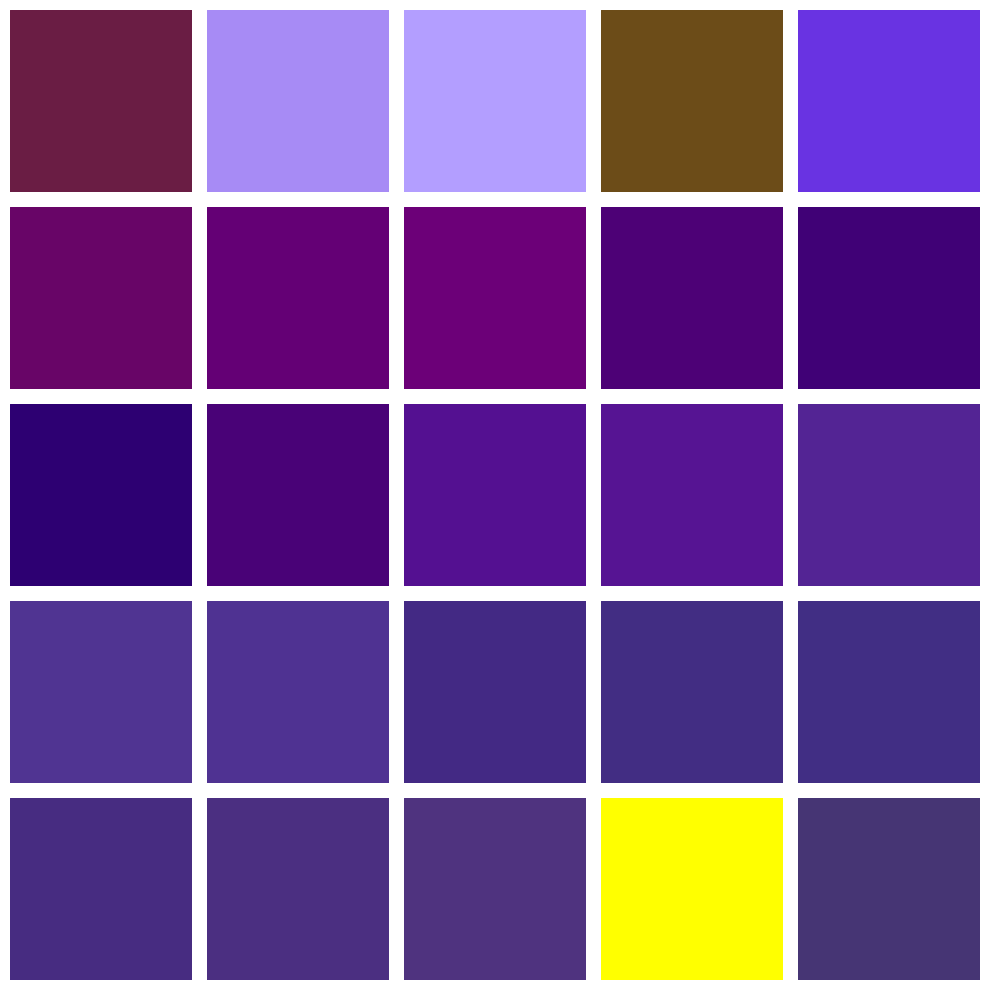

In [24]:
# Normalize RGB values to [0, 1] for visualization
normalized_rgb = [[r / 255, g / 255, b / 255] for r, g, b in optimized_rgb_values]

# Number of colors
num_colors = len(normalized_rgb)

# Define the grid
cols = 5  # Number of columns
rows = (num_colors + cols - 1) // cols  # Calculate rows required

# Create the figure
fig, ax = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))

# Plot each color
for i in range(rows):
    for j in range(cols):
        idx = i * cols + j
        if idx < num_colors:
            color = normalized_rgb[idx]
            ax[i, j].add_patch(plt.Rectangle((0, 0), 1, 1, color=color))
            ax[i, j].axis("off")
        else:
            ax[i, j].axis("off")  # Hide unused grid cells

plt.tight_layout()
plt.show()

### Use LHS

#### not optimal

In [4]:
# import pandas as pd
# import numpy as np

# # Convert RGB to normalized values
# optimized_normalized_rgb = [np.array(rgb) / 255 for rgb in optimized_rgb_values]

# # Function to generate Latin Hypercube samples with feedback
# def latin_hypercube_sum_constraint_feedback(n_samples, n_variables, sum_constraint, seed, feedback_weights):
#     np.random.seed(seed)
#     # Generate LHS samples
#     samples = np.random.uniform(0, 1, (n_samples, n_variables))
#     # Scale by sum constraint
#     samples *= sum_constraint / samples.sum(axis=1, keepdims=True)
#     # Incorporate feedback weights (e.g., bias toward optimized RGB)
#     weighted_samples = samples * feedback_weights
#     return weighted_samples / weighted_samples.sum(axis=1, keepdims=True) * sum_constraint

# # Define LHS parameters
# seeds = [1]
# # seeds = [2]
# arrays = []
# n_samples = 96
# n_variables = 4  # CMYK
# sum_constraint = 270.0

# # Define feedback weights (based on optimized RGB values)
# # This is a placeholder: adjust the weights based on RGB-to-CMYK mapping
# feedback_weights = np.ones(n_variables)  # Example: equal weight for all CMYK variables

# # Generate LHS samples with feedback
# for seed in seeds:
#     lhs_samples = latin_hypercube_sum_constraint_feedback(
#         n_samples=n_samples,
#         n_variables=n_variables,
#         sum_constraint=sum_constraint,
#         seed=seed,
#         feedback_weights=feedback_weights
#     )
#     arrays.append(lhs_samples.T)

# # Display the arrays
# for i, array in enumerate(arrays):
#     print(f"Results for seed {seeds[i]}:")
#     print("C (blue) values:")
#     print(", ".join(map(str, array[0])))
#     print("\nM (red) values:")
#     print(", ".join(map(str, array[1])))
#     print("\nY (yellow) values:")
#     print(", ".join(map(str, array[2])))
#     print("\nK (black) values:")
#     print(", ".join(map(str, array[3])))
#     print("\n" + "-" * 50 + "\n")

### RGB back to CMYK

In [13]:
import pandas as pd
import numpy as np

# Convert RGB to CMYK
def rgb_to_cmyk(r, g, b):
    r, g, b = r / 255, g / 255, b / 255  # Normalize RGB
    k = 1 - max(r, g, b)
    if k == 1:
        return 0, 0, 0, 1  # Handle edge case when K=1
    c = (1 - r - k) / (1 - k)
    m = (1 - g - k) / (1 - k)
    y = (1 - b - k) / (1 - k)
    return c, m, y, k

# Map optimized RGB values to CMYK
optimized_cmyk_values = [rgb_to_cmyk(*rgb) for rgb in optimized_rgb_values]

# Normalize CMYK values for feedback weights
optimized_normalized_cmyk = np.array(optimized_cmyk_values)

# Function to generate Latin Hypercube samples with feedback
def latin_hypercube_sum_constraint_feedback(n_samples, n_variables, sum_constraint, seed, feedback_weights):
    np.random.seed(seed)
    samples = np.random.uniform(0, 1, (n_samples, n_variables))
    samples *= sum_constraint / samples.sum(axis=1, keepdims=True)  # Scale to sum_constraint
    weighted_samples = samples * feedback_weights  # Apply feedback weights
    return weighted_samples / weighted_samples.sum(axis=1, keepdims=True) * sum_constraint

# Define LHS parameters
seeds = [2]
arrays = []
n_samples = 96
n_variables = 4  # CMYK
sum_constraint = 270.0

# Define feedback weights (e.g., average normalized CMYK values)
feedback_weights = optimized_normalized_cmyk.mean(axis=0)

# Generate LHS samples with feedback
for seed in seeds:
    lhs_samples = latin_hypercube_sum_constraint_feedback(
        n_samples=n_samples,
        n_variables=n_variables,
        sum_constraint=sum_constraint,
        seed=seed,
        feedback_weights=feedback_weights
    )
    arrays.append(lhs_samples.T)

# Display the arrays
for i, array in enumerate(arrays):
    print(f"Results for seed {seeds[i]}:")
    print("C (cyan) values:")
    print(", ".join(map(str, array[0])))
    print("\nM (magenta) values:")
    print(", ".join(map(str, array[1])))
    print("\nY (yellow) values:")
    print(", ".join(map(str, array[2])))
    print("\nK (black) values:")
    print(", ".join(map(str, array[3])))
    print("\n" + "-" * 50 + "\n")


Results for seed 2:
C (cyan) values:
99.85742885000515, 58.359036997558256, 48.08916424159009, 16.17315128819646, 104.78235718417751, 156.5297231202577, 21.92344559764362, 44.92535221095266, 76.30678443138423, 73.08209903307652, 97.71889064972534, 60.00346026155635, 52.223760949735365, 43.36849956275356, 35.7916322035725, 87.68272878487171, 51.523945725506294, 108.73870009655415, 31.749295897129095, 108.02854652896046, 121.70232764877431, 62.45937959137377, 195.99422621619, 74.03241153411572, 54.61041557450546, 94.48602958926614, 68.4424291064621, 63.00970755147926, 41.270411793686804, 95.65295093151157, 64.1180543805703, 20.156668415204766, 74.54262875316432, 35.71170519886891, 70.94918570205844, 117.78717934582626, 85.33768942180173, 35.16933774382813, 57.208752148064505, 9.120685582144663, 102.73923620258999, 55.70159768782896, 53.502610873304725, 8.2166015867707, 56.17860220657613, 34.3238132592026, 34.923080960978744, 5.34085135486697, 99.55922703844854, 77.25499539941244, 83.5568